# Day 42 Unsupervised Model - Decided Optimum Cluster

Pada notebook sebelumnya saya memakai K-Means dengan jumlah cluster `k=5` yang dipilih "begitu saja".

Tapi dari mana angka itu? Di proyek nyata ini harus **membuktikan** jumlah cluster yang paling masuk akal.

Notebook ini mengajarkan dua teknik klasik: **Metode Elbow (inertia)** dan **Silhouette Score**.

> 🎯 **Tujuan Pembelajaran**
> - Memahami apa itu *inertia* dan kenapa ia turun saat `k` membesar.
> - Menerapkan **Metode Elbow** untuk menebak `k` terbaik.
> - Menghitung **Silhouette Score** (seberapa rapi & terpisah cluster) untuk `k=2..10`.
> - Menggabungkan kedua metode untuk memilih `k` final secara meyakinkan.

## About Dataset

Saya memakai **Mall Customer Segmentation** — data pelanggan sebuah pusat
perbelanjaan yang berisi informasi pendapatan tahunan dan skor belanja.

- **Sumber:** [Kaggle — vjchoudhary7/customer-segmentation-tutorial-in-python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)
- **Jumlah data:** 200 baris × 5 kolom

| Kolom | Arti |
|-------|------|
| `CustomerID` | ID unik pelanggan |
| `Gender` | Jenis kelamin |
| `Age` | Usia |
| `Annual Income (k$)` | Pendapatan tahunan (ribu USD) |
| `Spending Score (1-100)` | Skor belanja (semakin tinggi = semakin royal) |

## Import Library

- **pandas / numpy** → olah data & angka.
- **matplotlib / seaborn** → visualisasi.
- **KMeans** → algoritma clustering.
- **StandardScaler** → menyamakan skala fitur sebelum clustering.
- **silhouette_score** → metrik kualitas cluster.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vjchoudhary7/customer-segmentation-tutorial-in-python
!unzip customer-segmentation-tutorial-in-python.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
License(s): other
100% 1.55k/1.55k [00:00<00:00, 3.54MB/s]

Archive:  customer-segmentation-tutorial-in-python.zip
  inflating: Mall_Customers.csv      


## Early Exploration Dataset

In [4]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


In [7]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 200
Jumlah kolom: 5
Missing Value: 0
Duplicate Data: 0


Lihat sekilas isi dan struktur data.

**Interpretasi:**

- Tiap baris adalah satu pelanggan. Saya akan fokus pada dua fitur perilaku: **Annual Income** (kemampuan belanja) dan **Spending Score** (kecenderungan belanja).
- Pendapatan berkisar 15–137 ribu USD dan skor belanja merata 1–99 — variasi yang bagus untuk clustering.
- Dataset terdiri dari 200 baris dan 5 kolom
- Tidak terdapat Missing Value dan Data Duplicate

## Preprocessing Data & Standarization

Saya pakai dua fitur: `Annual Income (k$)` dan `Spending Score (1-100)`.
K-Means menghitung **jarak** antar titik, sehingga fitur dengan rentang besar bisa "menang" tanpa alasan. Maka saya akan standardisasi (mean=0, std=1).

In [13]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Shape X_scaled: {X_scaled.shape}')
print(f'Rata rata setelah Scaled: {np.round(X_scaled.mean(axis=0), 2)}')
print(f'Standar deviasi setelah Scaled: {np.round(X_scaled.std(axis=0), 2)}')

Shape X_scaled: (200, 2)
Rata rata setelah Scaled: [-0. -0.]
Standar deviasi setelah Scaled: [1. 1.]


**Interpretasi:**
- Ukuran Data (200, 2): Dataset terdiri dari 200 baris sampel dan 2 kolom fitur.

- Rata-rata Menjadi 0 ([-0. -0.]): Titik pusat setiap fitur telah digeser ke angka nol.

- Standar Deviasi Menjadi 1 ([1. 1.]): Rentang penyebaran data pada tiap fitur telah diseragamkan menjadi satu.

Kesimpulan:
- Data telah berhasil distandarisasi menggunakan StandardScaler agar memiliki rata-rata 0 dan varians 1, yang merupakan tahap penting agar algoritma Machine Learning dapat memproses fitur secara adil tanpa ada yang mendominasi.

## Exploratory Data Analysis & Visualization

### a) Sebaran Pendapatan vs Skor Belanja

Sebelum clustering, lihat dulu sebaran mentahnya — apakah mata kita bisa menebak jumlah kelompok?

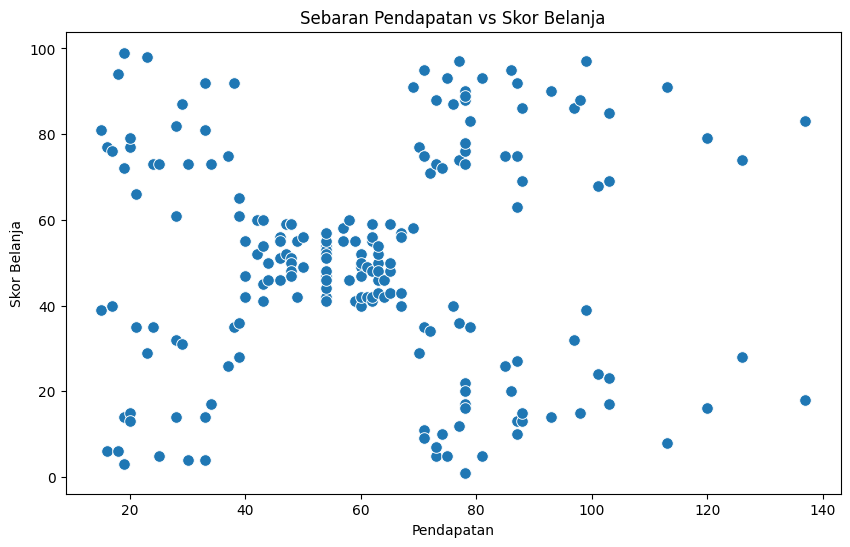

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Annual Income (k$)',
                y='Spending Score (1-100)',
                data=df,
                s=70)
plt.title('Sebaran Pendapatan vs Skor Belanja')
plt.xlabel('Pendapatan')
plt.ylabel('Skor Belanja')
plt.show()


**Interpretasi:**
- Sumbu X (Pendapatan): Menunjukkan tingkat pendapatan pelanggan.   
- Sumbu Y (Skor Belanja): Menunjukkan skor atau keaktifan belanja pelanggan.
- Pola Sebaran: Terlihat beberapa kelompok (klaster) titik data yang terpisah secara terkelompok.

Ini menunjukkan adanya beberapa segmen atau tipe pelanggan yang berbeda berdasarkan tingkat pendapatan dan kebiasaan belanja mereka (misalnya ada kelompok dengan pendapatan rendah/tinggi dengan skor belanja tinggi atau rendah).

### b) Metode Elbow (Inertia)


**Inertia** = total jarak kuadrat tiap titik ke centroid cluster-nya.
  - Tujuan: Mencari jumlah kelompok (cluster / $k$) yang paling pas untuk data .
  - Semakin banyak cluster, inertia pasti turun (ekstremnya: tiap titik jadi cluster sendiri → inertia 0).

Saya akan cari titik **"siku" (elbow)** — di mana penurunan inertia mulai melandai. Itulah `k` yang memberi keseimbangan terbaik.

In [17]:
K_range = range(1, 11)
inertia_list = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)


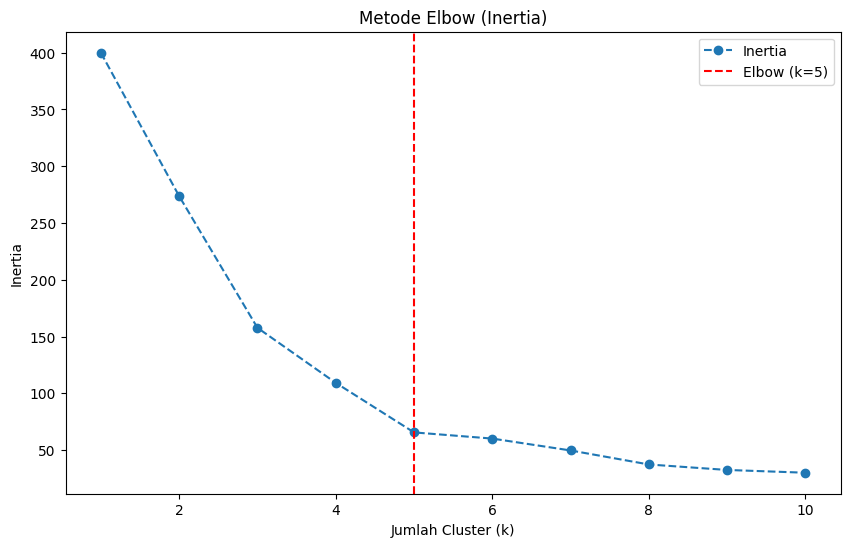

In [19]:
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia_list, marker='o', linestyle='--')
plt.title('Metode Elbow (Inertia)')
plt.axvline(x=5, color='red', linestyle='--')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.legend(['Inertia', 'Elbow (k=5)'])
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik tersebut:

  - Grafik Metode Elbow: Digunakan untuk menentukan jumlah kelompok (cluster atau $k$) yang paling optimal untuk data.   
  - Titik Siku ($k = 5$): Garis putus-putus merah menunjukkan bahwa titik siku (elbow) berada pada angka 5.   

Kesimpulan:
  - Jumlah cluster terbaik yang direkomendasikan adalah 5, karena setelah titik ini penurunan nilai inertia sudah mulai sangat landai dan tidak memberikan perubahan yang signifikan

### c) Silhouette Score

**Silhouette Score**:

* **Fungsi Utama:** Sebagai pelengkap metode *Elbow* untuk memastikan jumlah klaster ($k$) yang dipilih benar-benar optimal dan valid.

* **Cara Kerja:** Mengukur seberapa dekat suatu titik data dengan kelompoknya sendiri dibandingkan dengan kelompok (klaster) lain di sekitarnya.
  * **Cara Membaca Skor (Rentang -1 sampai 1):**
  * **Mendekati 1:** Klaster terbentuk dengan sangat rapi, padat di dalam, dan terpisah jelas dari klaster lain.
  * **Mendekati 0:** Ada titik-titik data yang posisinya berada di perbatasan antar klaster (*overlap*).
  * **Bernilai Negatif:** Titik data tersebut kemungkinan besar salah masuk kelompok (seharusnya berada di klaster lain).


* **Cara Menentukan Pilihan ($k$):** Cukup pilih jumlah klaster ($k$) yang menghasilkan **skor tertinggi** (paling mendekati 1), karena itu adalah konfigurasi klaster yang paling rapi dan terpisah paling tegas.

In [22]:
silhouette_scores = []

# Silhouette Score hanya bisa dihitung untuk k >= 2
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, labels)
    silhouette_scores.append(silhouette_avg)
    print(f'k={k}: Silhouette Score = {silhouette_avg:.4f}')

k=2: Silhouette Score = 0.3973
k=3: Silhouette Score = 0.4666
k=4: Silhouette Score = 0.4943
k=5: Silhouette Score = 0.5547
k=6: Silhouette Score = 0.5138
k=7: Silhouette Score = 0.5020
k=8: Silhouette Score = 0.4550
k=9: Silhouette Score = 0.4567
k=10: Silhouette Score = 0.4448


**Interpretasi:**

* **Nilai Silhouette Score Terbesar:** Terlihat bahwa skor tertinggi diperoleh saat **k = 5** dengan nilai **0.5546** (sekitar 0.55).
* **Analisis Perbandingan k:**
  * `k=2` memiliki skor terendah (~0.39).
  * Skor terus naik hingga mencapai puncaknya di `k=5` (~0.55).
  * Setelah `k=5`, nilai skor kembali menurun secara konstan.

**Kesimpulan:**
Analisis menggunakan **Silhouette Score** ini memperkuat dan memvalidasi hasil dari **Metode Elbow** sebelumnya. Kedua metode sepakat bahwa **k = 5** adalah jumlah klaster paling optimal, padat, dan terpisah secara maksimal untuk dataset ini.

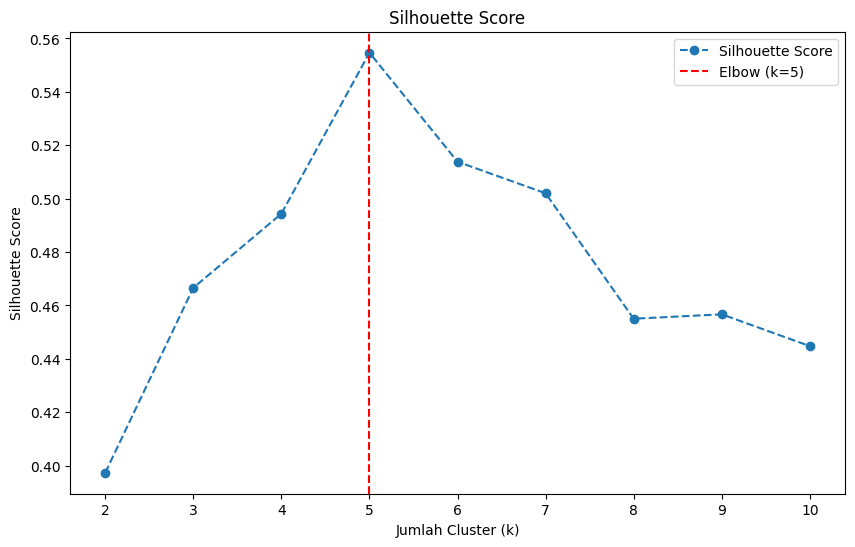

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.axvline(x=5, color='red', linestyle='--')
plt.legend(['Silhouette Score', 'Elbow (k=5)'])
plt.show()

Berikut adalah interpretasi sederhana dari grafik *Silhouette Score* tersebut:

* **Puncak Tertinggi ($k = 5$):** Garis putus-putus merah menunjukkan bahwa skor tertinggi berada tepat di angka **5** (mencapai sekitar 0.55).


* **Validasi Klaster:** Karena titik puncak tertinggi ada di $k = 5$, ini memperkuat bukti bahwa pembagian data menjadi **5 klaster** adalah pilihan yang paling optimal dan rapi.

## Modeling with Optimum K

Kita latih K-Means final dengan `k=5` lalu visualisasikan hasilnya beserta centroid.

In [27]:
k_final = 5
kmeans_final = KMeans(n_clusters=k_final,
                      random_state=42,
                      n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

df.head(2)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2


In [32]:
#centroid
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)
print("Centroids:")
print("[Pendapatan, Skor Belanja]")
print(np.round(centroids, 2))

Centroids:
[Pendapatan, Skor Belanja]
[[55.3  49.52]
 [86.54 82.13]
 [25.73 79.36]
 [88.2  17.11]
 [26.3  20.91]]


**Interpretasi Centroid (Nilai Pusat Kelompok):**

Berikut adalah ringkasan profil ke-5 segmen pelanggan berdasarkan titik pusat (*centroid*) tersebut:

1. **[55.30, 49.52] (Menengah-Menengah):** Pelanggan reguler dengan pendapatan dan pengeluaran yang seimbang di tengah-tengah.
2. **[86.54, 82.13] (Pendapatan Tinggi, Belanja Tinggi):** Pelanggan prioritas/sultan yang royal dan aktif berbelanja.
3. **[25.73, 79.36] (Pendapatan Rendah, Belanja Tinggi):** Pelanggan yang gemar berbelanja meskipun pendapatan mereka terbatas.
4. **[88.20, 17.11] (Pendapatan Tinggi, Belanja Rendah):** Pelanggan kaya raya namun sangat selektif atau hemat dalam berbelanja.
5. **[26.30, 20.91] (Pendapatan Rendah, Belanja Rendah):** Pelanggan dengan daya beli dan aktivitas belanja yang rendah.

Interpretasi ini sangat ideal untuk dijadikan dasar strategi marketing yang berbeda bagi masing-masing kelompok!

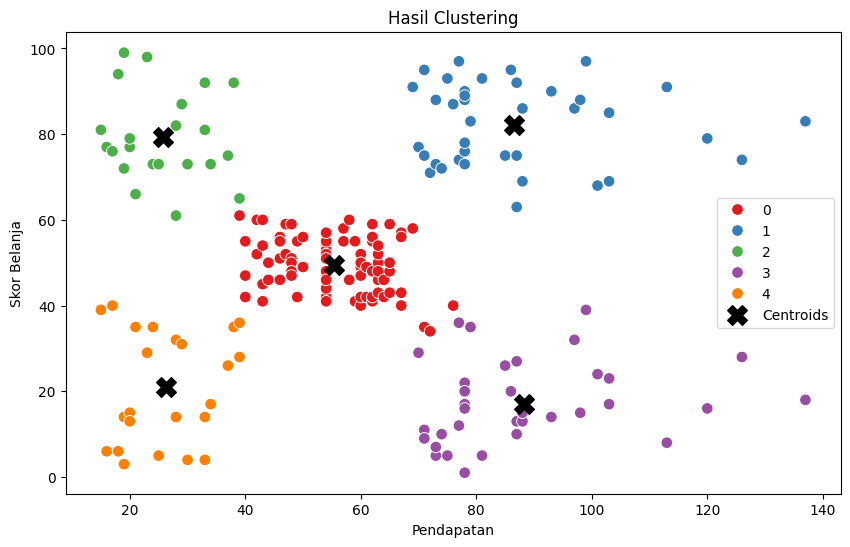

In [33]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Annual Income (k$)',
                y='Spending Score (1-100)',
                hue='Cluster',
                palette='Set1',
                data=df,
                s=70)
plt.scatter(x=centroids[:, 0],
            y=centroids[:, 1],
            marker='X',
            c='black',
            s=200,
            label='Centroids')

plt.title('Customer Segmentation')
plt.xlabel('Pendapatan')
plt.ylabel('Skor Belanja')
plt.legend()
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik hasil *clustering* tersebut:

* **Visualisasi Klaster:** Grafik ini menunjukkan hasil akhir pengelompokan data pelanggan menjadi **5 kelompok (0 sampai 4)** yang ditandai dengan warna berbeda.


* **Titik Pusat (Centroid):** Tanda silang hitam besar ($\mathbf{X}$) di tengah-tengah setiap warna menunjukkan titik pusat (*centroid*) dari masing-masing klaster.


**Kesimpulan:**
- Algoritma berhasil memetakan dan mengelompokkan pelanggan dengan sangat rapi sesuai pola pendapatan dan skor belanjanya (misalnya kelompok hijau untuk pendapatan rendah-belanja tinggi, biru untuk pendapatan tinggi-belanja tinggi, dan seterusnya).

## Insight and Conclusion

Berdasarkan hasil analisis segmentasi menggunakan **K-Means Clustering (k=5)**, berikut adalah kesimpulan dan rekomendasi strategi bisnis (actionable insights) untuk setiap kelompok pelanggan:

### 📊 Ringkasan Karakteristik Segmen Pelanggan

| Cluster | Nama Segmen | Karakteristik (Pendapatan vs Pengeluaran) | Strategi Pemasaran Terarah (Action Plan) |
| :---: | :--- | :--- | :--- |
| **0** | **Menengah-Menengah** | Pendapatan sedang (55.3k) dan pengeluaran sedang (49.52). | Berikan promo musiman rutin, loyalitas kartu member standar, dan rekomendasi produk terpopuler agar mereka tetap konsisten berbelanja. |
| **1** | **Prioritas / Sultan** | Pendapatan tinggi (86.54k) dan pengeluaran tinggi (82.13). | **Target Utama!** Berikan program eksklusif (VIP loyalty program), akses awal produk baru, undangan acara khusus, dan layanan personal shopper. |
| **2** | **Impulsif / Pemburu Diskon** | Pendapatan rendah (25.73k) namun pengeluaran tinggi (79.36). | Fokuskan pada penawaran cicilan/paylater, promosi kilat (*flash sale*), *bundling* produk hemat, dan diskon menarik di media sosial. |
| **3** | **Potensial Hemat** | Pendapatan tinggi (88.2k) namun pengeluaran rendah (17.11). | Tawarkan produk berkualitas tinggi/premium yang menekankan nilai investasi jangka panjang atau kegunaan fungsional (*utility-focused ads*). |
| **4** | **Hemat / Minimalis** | Pendapatan rendah (26.3k) dan pengeluaran rendah (20.91). | Rekomendasikan barang-barang kebutuhan pokok yang murah, promo diskon langsung (*clearance sale*), atau produk dalam kemasan ekonomis. |

---

### 🏆 Kesimpulan Utama
1. **Validasi Jumlah Kelompok:** Kombinasi **Metode Elbow** dan **Silhouette Score** berhasil membuktikan secara ilmiah bahwa membagi pelanggan mall menjadi **5 kelompok** adalah strategi segmentasi yang paling akurat dan optimal.
2. **Efisiensi Anggaran Pemasaran:** Dengan mengetahui segmen-segmen ini, tim pemasaran tidak perlu membuang anggaran untuk mengirimkan promosi massal yang sama ke semua orang. Strategi pemasaran kini bisa disesuaikan secara personal dan tepat sasaran.